# Activité pratique n°1 — Mise en œuvre du framework PyTorch

**Enseignant :** Mohamed YOUSSFI

**Nom :** À compléter

**Prénom :** À compléter

**Groupe :** À compléter

Ce notebook reprend la démonstration du framework, puis résout les quatre exercices dans l'ordre du sujet :

1. régression des salaires ;
2. classification Iris ;
3. MNIST avec un perceptron multicouche (MLP) ;
4. MNIST avec un réseau convolutif (CNN).

Les explications visent la relecture et la présentation : forme des tenseurs, rôle des lignes importantes, et lecture des résultats réellement calculés.

## Note sur la vidéo de démonstration

Référence : [Part 1 — Neural Network Fundamentals with PyTorch For Generative AI](https://www.youtube.com/watch?v=vCbEmtrR0_w), chaîne du professeur Mohamed YOUSSFI.

Le titre et l'auteur de la vidéo ont pu être vérifiés. Aucune piste de sous-titres n'est exposée par l'API de transcription (`timedtext` renvoie un document vide), donc les manipulations n'ont pas pu être revues image par image. La partie 1 suit les sections de démonstration du notebook fourni, corrigées lorsque le code ou le Markdown empêchait l'exécution ou le rendu.

# Partie 1 — Démonstration PyTorch

**Objectifs :**

- comprendre les `Tensor` et l'appareil de calcul ;
- utiliser `autograd` et vérifier les gradients à la main ;
- construire un modèle avec `nn.Linear`, `nn.Module` et `nn.Sequential` ;
- définir une perte, un optimiseur et la boucle `zero_grad → forward → loss → backward → step` ;
- distinguer `train()`, `eval()`, `torch.no_grad()` et `torch.inference_mode()` ;
- utiliser `TensorDataset` et `DataLoader` ;
- entraîner une régression et une classification, puis sauvegarder les poids.

## 0. Préparation

Le notebook tourne sur CPU sous Windows. Si CUDA est disponible, les modèles et les lots sont placés sur le GPU. Les tenseurs sont ramenés sur le CPU avant NumPy et Matplotlib. Sous Windows, `num_workers=0` évite les blocages du `DataLoader` dans un notebook.

In [1]:
%matplotlib inline
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import numpy as np

def fixer_graine(graine=42):
    # Reproduit les tirages PyTorch sur CPU et, s'il existe, sur CUDA.
    torch.manual_seed(graine)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(graine)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Obligatoire dans ce notebook Windows : pas de workers séparés.
NUM_WORKERS = 0
resultats = {}

print("PyTorch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
print("Appareil utilisé :", device)
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

PyTorch : 2.15.0+cpu
CUDA disponible : False
Appareil utilisé : cpu


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

Chaque époque répète cinq actions, dans cet ordre : remettre les gradients à zéro, calcul avant, perte, rétropropagation, pas d'optimisation.

In [2]:
# Pseudo-code de la logique générale
# optimizer.zero_grad()
# y_pred = model(X)
# loss = criterion(y_pred, y)
# loss.backward()
# optimizer.step()
print("Boucle retenue : zero_grad → forward → loss → backward → step")

Boucle retenue : zero_grad → forward → loss → backward → step


## 2. Les tenseurs

Un `Tensor` est le tableau multidimensionnel de PyTorch. Un scalaire a 0 dimension, un vecteur en a 1, une matrice en a 2. `shape` donne la taille de chaque axe, `dtype` le type numérique, `ndim` le rang.

In [3]:
scalaire = torch.tensor(3.0)
vecteur = torch.tensor([1.0, 2.0, 3.0])
matrice = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalaire :", scalaire, "| shape =", tuple(scalaire.shape), "| ndim =", scalaire.ndim)
print("vecteur  :", vecteur, "| shape =", tuple(vecteur.shape), "| ndim =", vecteur.ndim)
print("matrice  :", matrice, "| shape =", tuple(matrice.shape), "| ndim =", matrice.ndim)
print("dtype de la matrice :", matrice.dtype)
print("appareil de la matrice :", matrice.device)

scalaire : tensor(3.) | shape = () | ndim = 0
vecteur  : tensor([1., 2., 3.]) | shape = (3,) | ndim = 1
matrice  : tensor([[1., 2.],
        [3., 4.]]) | shape = (2, 2) | ndim = 2
dtype de la matrice : torch.float32
appareil de la matrice : cpu


La forme `()` du scalaire signifie un tenseur à zéro axe qui contient pourtant une valeur. Le vecteur a la forme `(3,)` : trois composantes, un seul axe. La matrice a la forme `(2, 2)`.

### Manipulation : indexation, `reshape`, produit matriciel

`torch.arange(12)` produit les entiers de 0 à 11, forme `(12,)`. `reshape(3, 4)` les réorganise sans changer les valeurs : 3 lignes et 4 colonnes. L'indexation suit l'ordre *ligne, colonne*. `A @ B` est le produit matriciel, distinct du produit terme à terme `A * B`.

In [4]:
x = torch.arange(12)
print("x =", x, "| shape =", tuple(x.shape))

x2 = x.reshape(3, 4)
print("reshape(3, 4) =\n", x2)

print("Colonne 1 (deuxième colonne) :", x2[:, 1])
print("Ligne 0 :", x2[0, :])

A = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
B = torch.tensor([[2.0, 0.0], [1.0, 2.0]])
print("A @ B =\n", A @ B)
print("mean(A) =", A.mean().item())
print("sum(A) =", A.sum().item())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]) | shape = (12,)
reshape(3, 4) =
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1 (deuxième colonne) : tensor([1, 5, 9])
Ligne 0 : tensor([0, 1, 2, 3])
A @ B =
 tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = 2.5
sum(A) = 10.0


Lecture de `x2` :

$$
\begin{bmatrix}
0 & 1 & 2 & 3 \\
4 & 5 & 6 & 7 \\
8 & 9 & 10 & 11
\end{bmatrix}
$$

La colonne 1 vaut donc `[1, 5, 9]` et la ligne 0 vaut `[0, 1, 2, 3]`.

Le produit demandé se calcule ainsi :

$$
A B =
\begin{bmatrix}
1\cdot 2 + 2\cdot 1 & 1\cdot 0 + 2\cdot 2 \\
3\cdot 2 + 4\cdot 1 & 3\cdot 0 + 4\cdot 2
\end{bmatrix}
=
\begin{bmatrix}
4 & 4 \\
10 & 8
\end{bmatrix}
$$

La somme des huit éléments de `A` est 10, leur moyenne est 1,25. Ces affichages confirment que l'indexation et le produit matriciel portent sur les bons axes.

## 3. CPU, GPU et `device`

`torch.cuda.is_available()` détecte un GPU NVIDIA utilisable. Le tenseur est ensuite envoyé explicitement avec `.to(device)`. Un calcul mélangeant CPU et CUDA lève une erreur : le modèle et les lots doivent partager le même appareil.

In [5]:
print("Device utilisé :", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x =", x)
print("x.device =", x.device)
print("x.shape =", tuple(x.shape))

Device utilisé : cpu
x = tensor([1., 2., 3.])
x.device = cpu
x.shape = (3,)


## 4. Autograd

`autograd` construit un graphe des opérations dès qu'un tenseur a `requires_grad=True`, puis dérive la perte par rapport à ces tenseurs.

On reprend l'exemple du support :

$$
y = wx + b, \quad x = 2,\ w = 3,\ b = 1, \quad L = (y - 10)^2.
$$

D'où $y = 7$ et $L = 9$. La règle de chaîne donne les valeurs de contrôle :

$$
\frac{\partial L}{\partial y} = 2(y - 10) = -6, \qquad
\frac{\partial L}{\partial w} = \frac{\partial L}{\partial y}\, x = -12, \qquad
\frac{\partial L}{\partial b} = \frac{\partial L}{\partial y} = -6.
$$

`loss.backward()` remplit `.grad` **et libère le graphe**. Un second appel sur le même graphe échouerait. La cellule suivante reconstruit donc `y` et `loss` avant `torch.autograd.grad`.

In [6]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dL/dw =", w.grad.item())
print("dL/db =", b.grad.item())

assert y.item() == 7.0
assert loss.item() == 9.0
assert w.grad.item() == -12.0
assert b.grad.item() == -6.0
print("Gradients backward() conformes aux valeurs de contrôle -12 et -6.")

y = 7.0
loss = 9.0
dL/dw = -12.0
dL/db = -6.0
Gradients backward() conformes aux valeurs de contrôle -12 et -6.


`torch.autograd.grad(loss, (w, b))` renvoie les mêmes dérivées sans les stocker dans `.grad`. Il consomme lui aussi le graphe, d'où la reconstruction.

In [7]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dL/dw =", dw.item())
print("dL/db =", db.item())
assert dw.item() == -12.0 and db.item() == -6.0
print("torch.autograd.grad confirme dL/dw = -12 et dL/db = -6.")

y = 7.0
loss = 9.0
dL/dw = -12.0
dL/db = -6.0
torch.autograd.grad confirme dL/dw = -12 et dL/db = -6.


### Vérification analytique

Les formules du support étaient cassées par un caractère de contrôle à la place de `\frac`. Les dérivées correctes sont :

$$
\frac{\partial L}{\partial w} = 2(y - 10)\, x, \qquad
\frac{\partial L}{\partial b} = 2(y - 10).
$$

Avec $y = 3 \times 2 + 1 = 7$ :

$$
\frac{\partial L}{\partial w} = 2(7 - 10)\times 2 = -12, \qquad
\frac{\partial L}{\partial b} = 2(7 - 10) = -6.
$$

In [8]:
y_val = 3.0 * 2.0 + 1.0
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
y = w * x + b
loss = (y - 10) ** 2
loss.backward()

print("y analytique =", y_val, "| y PyTorch =", y.item())
print("manuel  dL/dw, dL/db =", dL_dw, dL_db)
print("backward dL/dw, dL/db =", w.grad.item(), b.grad.item())
print(
    "Concordance manuel / PyTorch :",
    math.isclose(dL_dw, w.grad.item()) and math.isclose(dL_db, b.grad.item()),
)

y analytique = 7.0 | y PyTorch = 7.0
manuel  dL/dw, dL/db = -12.0 -6.0
backward dL/dw, dL/db = -12.0 -6.0
Concordance manuel / PyTorch : True


**Conclusion.** Les trois calculs — `backward()`, `torch.autograd.grad()` et la dérivation à la main — donnent les mêmes valeurs, $y = 7$, $L = 9$, $\partial L / \partial w = -12$ et $\partial L / \partial b = -6$. Le graphe automatique est donc fiable sur cet exemple, à condition de le reconstruire après chaque dérivation.

## 5. Un neurone avec `nn.Linear`

`nn.Linear(in_features, out_features)` calcule, pour chaque exemple du lot :

$$
z = x W^\top + b.
$$

Le paramètre `weight` a la forme `(out_features, in_features)` et `bias` la forme `(out_features,)`. Les poids sont initialisés aléatoirement : la sortie change d'une exécution à l'autre tant qu'on ne fixe pas la graine juste avant la création du module.

In [9]:
fixer_graine(0)
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Entrée :", tuple(x.shape), "→ (taille du lot, variables)")
print("Sortie :", y.detach(), "| shape =", tuple(y.shape), "→ (taille du lot, neurones)")
print("Poids :", model.weight.detach(), "| shape =", tuple(model.weight.shape))
print("Biais :", model.bias.detach(), "| shape =", tuple(model.bias.shape))
print("Poids et biais exigent un gradient :", model.weight.requires_grad, model.bias.requires_grad)

Entrée : (1, 3) → (taille du lot, variables)
Sortie : tensor([[-1.2353]]) | shape = (1, 1) → (taille du lot, neurones)
Poids : tensor([[-0.0043,  0.3097, -0.4752]]) | shape = (1, 3)
Biais : tensor([-0.4249]) | shape = (1,)
Poids et biais exigent un gradient : True True


### Graphe des opérations avec `torchviz`

Si le paquet `torchviz` ou le programme Graphviz (`dot`) manque, le dessin est omis et le reste du notebook continue. Le neurone linéaire, lui, a déjà été exécuté dans la cellule précédente.

In [10]:
fixer_graine(0)
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)
print("Sortie :", y.detach())
print("Poids :", model.weight.detach())
print("Biais :", model.bias.detach())

try:
    from torchviz import make_dot
    diagramme = make_dot(y, params=dict(model.named_parameters()))
    diagramme.render("graphe_operations", format="png", cleanup=True)
    print("Graphe enregistré dans graphe_operations.png")
except Exception as exc:
    print("Visualisation torchviz non générée : Graphviz ou torchviz est indisponible.")
    print("Détail :", type(exc).__name__, ":", exc)
    print("Seul le dessin est omis. Le calcul du neurone linéaire reste valide.")

Sortie : tensor([[-1.2353]])
Poids : tensor([[-0.0043,  0.3097, -0.4752]])
Biais : tensor([-0.4249])
Visualisation torchviz non générée : Graphviz ou torchviz est indisponible.
Détail : ModuleNotFoundError : No module named 'torchviz'
Seul le dessin est omis. Le calcul du neurone linéaire reste valide.


## 6. Construire un réseau avec `nn.Module`

Sous-classer `nn.Module` permet de nommer les blocs et d'écrire `forward`. `nn.Sequential` enchaîne les mêmes couches lorsque le flux est purement linéaire. Les deux définitions ci-dessous décrivent le même réseau : 4 entrées, couche cachée de 16 avec ReLU, couche cachée de 8 avec ReLU, 3 sorties.

La seconde cellule réaffecte `model`. C'est cette version `Sequential` qui sert au passage avant de la section 8.

In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )

    def forward(self, x):
        return self.net(x)

mlp = MLP()
print(mlp)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [12]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3),
)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d'activation

ReLU annule les valeurs négatives et laisse passer les positives. `tanh` envoie $\mathbb{R}$ dans $(-1, 1)$. La sigmoïde l'envoie dans $(0, 1)$. ReLU est l'activation utilisée dans les réseaux de ce TP, parce qu'elle ne sature pas pour les valeurs positives et reste simple à dériver.

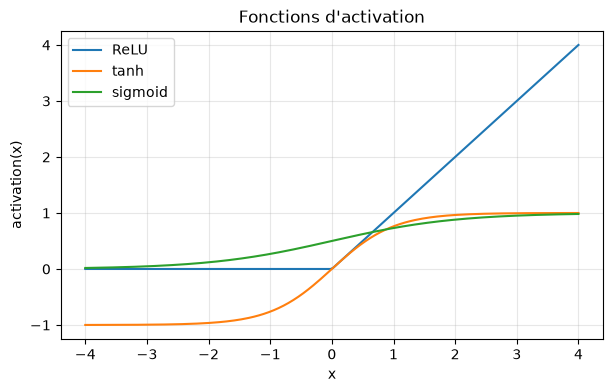

In [13]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7, 4))
plt.plot(x.cpu().numpy(), relu.cpu().numpy(), label="ReLU")
plt.plot(x.cpu().numpy(), tanh.cpu().numpy(), label="tanh")
plt.plot(x.cpu().numpy(), sigmoid.cpu().numpy(), label="sigmoid")
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.xlabel("x")
plt.ylabel("activation(x)")
plt.show()

## 8. Propagation avant

L'appel `model(X)` exécute `forward`. Ici chaque exemple a 4 variables et le réseau produit 3 scores. Avec 5 exemples, les formes passent de `(5, 4)` à `(5, 3)`. Ces 3 nombres sont des logits : ils ne sont pas encore des probabilités.

In [14]:
X = torch.randn(5, 4)
predicted = model(X)
print("Shape entrée :", tuple(X.shape))
print("Shape sortie :", tuple(predicted.shape))

Shape entrée : (5, 4)
Shape sortie : (5, 3)


## 9. Fonctions de coût

- **Régression** : `MSELoss`, moyenne des carrés des écarts. Les cibles sont des réels, de même forme que la prédiction.
- **Classification multi-classe** : `CrossEntropyLoss`. Elle attend des **logits** et des étiquettes entières (indice de classe), pas des probabilités ni un one-hot.
- **Classification binaire à un seul logit** : `BCEWithLogitsLoss`. Les cibles sont alors des flottants 0 ou 1.

`CrossEntropyLoss` applique elle-même un `log_softmax`. Ajouter un `Softmax` dans le modèle fausserait la perte.

In [15]:
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())
print("Vérification manuelle :", ((y_pred - y_true) ** 2).mean().item())

criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())
print("Forme des logits :", tuple(pred.shape), "| étiquettes :", y.dtype)

criterion_bce = nn.BCEWithLogitsLoss()
logit_binaire = torch.tensor([[0.5], [-1.0]])
cible_binaire = torch.tensor([[1.0], [0.0]])
print("BCEWithLogits =", criterion_bce(logit_binaire, cible_binaire).item())

MSE = 1.0
Vérification manuelle : 1.0
CrossEntropy = 0.36905235052108765
Forme des logits : (2, 3) | étiquettes : torch.int64
BCEWithLogits = 0.39366936683654785


La MSE manuelle vaut $(1^2 + 1^2) / 2 = 1$. L'égalité avec `MSELoss` confirme la définition. Pour la cross-entropy, le premier exemple a sa plus grande coordonnée sur la classe 0, qui est la bonne étiquette ; le second est maximal sur la classe 2, également correcte. La perte reste positive : un logit « gagnant » n'est pas une probabilité 1.

## 10. Optimiseurs

L'optimiseur ne calcule pas les gradients. Il lit `.grad`, déjà rempli par `backward()`, et met à jour les paramètres. Adam adapte un pas par paramètre. La démonstration de régression plus bas utilise Adam ; l'exercice des salaires impose SGD.

In [16]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d'apprentissage

Sur un jouet $y = 2x + 1$, sans bruit, un neurone linéaire peut retrouver la pente et l'ordonnée à l'origine.

Ordre retenu à chaque époque :

1. `optimizer.zero_grad()` efface les gradients de l'itération précédente, sinon ils s'additionnent ;
2. le forward produit `y_pred` ;
3. la perte compare `y_pred` et `y` ;
4. `loss.backward()` dérive la perte ;
5. `optimizer.step()` modifie les poids dans le sens qui diminue la perte.

`model.train()` est appelé au début de l'époque. Sur une couche linéaire pure, il ne change pas le calcul ; il deviendra important dès qu'il y aura un dropout.

In [17]:
fixer_graine(1)
X = torch.randn(8, 1, device=device)
y = 2 * X + 1
simple_model = nn.Linear(1, 1).to(device)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()

for epoch in range(500):
    simple_model.train()
    optimizer.zero_grad()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"epoch={epoch} loss={loss.item():.4f}")

print(
    f"Pente apprise = {simple_model.weight.item():.3f} (cible 2), "
    f"biais = {simple_model.bias.item():.3f} (cible 1)"
)

epoch=0 loss=2.4855
epoch=100 loss=0.4598
epoch=200 loss=0.0687


epoch=300 loss=0.0065
epoch=400 loss=0.0003
Pente apprise = 1.995 (cible 2), biais = 1.000 (cible 1)


La perte descend et les paramètres se rapprochent de 2 et 1. Comme il n'y a pas de bruit et que le modèle a exactement la bonne forme, l'erreur peut devenir très petite. Ce ne sera plus le cas des salaires, où un bruit gaussien empêche une perte nulle.

## 12. `train()`, `eval()`, `no_grad()` et `inference_mode()`

Ces mécanismes ne font pas le même travail.

- `model.train()` active le comportement d'apprentissage de `Dropout` et de `BatchNorm` (masques aléatoires, statistiques du lot).
- `model.eval()` fige ce comportement pour la prédiction (le dropout devient l'identité, BatchNorm utilise les statistiques cumulées). **Il n'arrête pas le calcul des gradients.**
- `torch.no_grad()` désactive la construction du graphe. On s'en sert pour évaluer sans consommer de mémoire d'autograd.
- `torch.inference_mode()` va un cran plus loin : les tenseurs produits ne peuvent plus entrer dans un graphe. C'est le mode adapté à une inférence pure.

La cellule suivante le montre avec un dropout de probabilité 0,5. En apprentissage, une partie des 1 est mise à 0 et le reste est amplifié par $1/(1-0{,}5) = 2$. En évaluation, le vecteur de 1 est restitué tel quel.

In [18]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval() + inference_mode :", m(x))

# En eval(), Dropout renvoie le tenseur d'entrée lui-même. Ce retour
# identique masquerait l'effet de no_grad. La sonde linéaire crée un
# vrai nouveau tenseur, donc le drapeau requires_grad est observable.
sonde = nn.Linear(10, 4)
x_grad = torch.ones(1, 10, requires_grad=True)
sonde.eval()
y_eval = sonde(x_grad)
print("eval() seul, requires_grad de la sortie :", bool(y_eval.requires_grad))

with torch.no_grad():
    y_ng = sonde(x_grad)
print("torch.no_grad(), requires_grad de la sortie :", bool(y_ng.requires_grad))

with torch.inference_mode():
    y_inf = sonde(x_grad)
print("torch.inference_mode(), requires_grad de la sortie :", bool(y_inf.requires_grad))

train() : tensor([2., 0., 2., 0., 2., 2., 2., 0., 2., 0.])
eval() + inference_mode : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])
eval() seul, requires_grad de la sortie : True
torch.no_grad(), requires_grad de la sortie : False
torch.inference_mode(), requires_grad de la sortie : False


La ligne `train()` mélange des 0 et des 2 : le masque est aléatoire et les valeurs gardées sont amplifiées. La ligne `eval()` restitue exactement les dix 1. Le contrôle de gradient passe par une couche linéaire, parce que le dropout en évaluation ne crée pas de nouveau tenseur. Sous `eval()` seul, la sortie garde `requires_grad=True` : ce mode ne remplace ni `no_grad()` ni `inference_mode()`. Ces deux contextes mettent `requires_grad` à faux.

## 13. `TensorDataset` et `DataLoader`

`TensorDataset` associe, ligne à ligne, les entrées et les cibles. `DataLoader` découpe ce couple en mini-lots. `shuffle=True` change l'ordre à chaque parcours, ce qui stabilise mieux la descente de gradient qu'un ordre toujours identique.

Ici, 100 exemples et des lots de 16 donnent six lots complets et un dernier lot de 4. Le dernier lot plus court est la raison pour laquelle une perte moyenne d'époque doit être pondérée par la taille de chaque lot.

In [19]:
fixer_graine(0)
X = torch.randn(100, 3)
y = torch.randn(100, 1)
jeu = TensorDataset(X, y)
loader = DataLoader(jeu, batch_size=16, shuffle=True, num_workers=NUM_WORKERS)

tailles = []
for X_batch, y_batch in loader:
    tailles.append(X_batch.shape[0])

print("Premier lot observé au tour suivant, tailles de tous les lots :", tailles)
X_batch, y_batch = next(iter(loader))
print("Batch X :", tuple(X_batch.shape), "| Batch y :", tuple(y_batch.shape))
print("Appareil du lot :", X_batch.device)
print("Nombre de lots :", len(loader))

Premier lot observé au tour suivant, tailles de tous les lots :

 [16, 16, 16, 16, 16, 16, 4]
Batch X : (16, 3) | Batch y : (16, 1)
Appareil du lot : cpu
Nombre de lots : 7


# Démonstration complète 1 — Régression linéaire

Les abscisses sont 120 valeurs régulièrement espacées entre −2 et 2. La cible suit

$$
y = 3x + 2 + \text{bruit},
$$

avec un bruit gaussien d'écart-type 0,6. Le modèle n'a pas le droit de connaître 3 et 2 : il ne voit que les couples $(x, y)$. Il n'y a pas de jeu de test dans cette démonstration. Le $R^2$ calculé plus bas est donc un score **sur les données d'entraînement**.

X : (120, 1) | y : (120, 1)


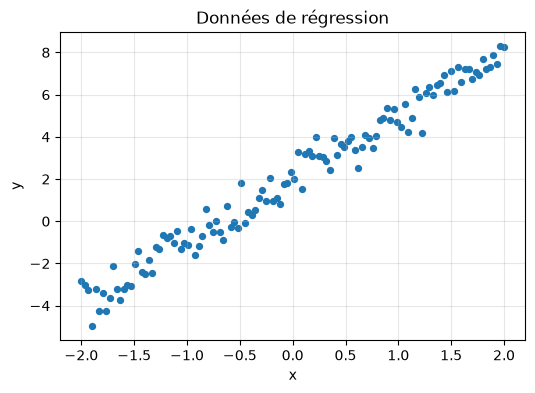

In [20]:
fixer_graine(42)
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
bruit = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + bruit
print("X :", tuple(X.shape), "| y :", tuple(y.shape))

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

X = X.to(device)
y = y.to(device)

## 14 et 15. Modèle, perte, optimiseur et entraînement

`nn.Linear(1, 1)` est exactement une droite $y = wx + b$. La perte est la MSE. Adam, avec un pas de 0,05, ajuste $w$ et $b$ pendant 300 époques. On s'attend à retrouver une pente proche de 3 et un biais proche de 2, sans les atteindre exactement à cause du bruit.

In [21]:
model_reg = nn.Linear(1, 1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

losses = []
for epoch in range(300):
    model_reg.train()
    optimizer.zero_grad()
    y_pred = model_reg(X)
    loss = criterion(y_pred, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print("Dernière perte :", losses[-1])
print("w appris :", model_reg.weight.item())
print("b appris :", model_reg.bias.item())
resultats["demo_regression"] = {
    "perte": losses[-1],
    "w": model_reg.weight.item(),
    "b": model_reg.bias.item(),
}

Dernière perte : 0.3438417613506317
w appris : 2.9894580841064453
b appris : 2.030014991760254


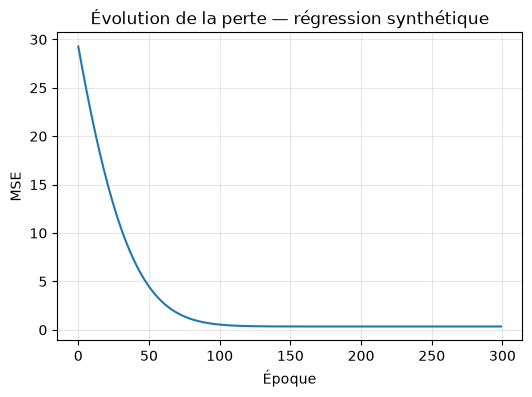

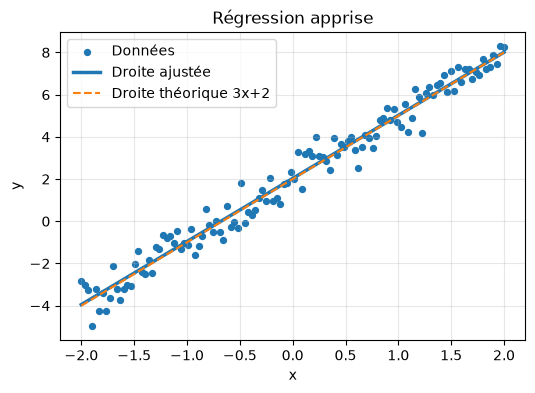

R2 sur les données d'entraînement de la démonstration = 0.972


In [22]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("MSE")
plt.title("Évolution de la perte — régression synthétique")
plt.grid(True, alpha=0.3)
plt.show()

model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

x_cpu = X.detach().cpu().numpy()
y_cpu = y.detach().cpu().numpy()
y_hat_cpu = y_hat.detach().cpu().numpy()

plt.figure(figsize=(6, 4))
plt.scatter(x_cpu, y_cpu, s=18, label="Données")
plt.plot(x_cpu, y_hat_cpu, linewidth=2.5, label="Droite ajustée")
plt.plot(x_cpu, 3 * x_cpu + 2, linewidth=1.5, linestyle="--", label="Droite théorique 3x+2")
plt.legend()
plt.title("Régression apprise")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

# Le support importe torcheval.metrics.R2Score. scikit-learn calcule
# le même coefficient de détermination, sans dépendance supplémentaire.
from sklearn.metrics import r2_score

r2 = r2_score(y_cpu, y_hat_cpu)
print(f"R2 sur les données d'entraînement de la démonstration = {r2:.3f}")
resultats["demo_regression"]["r2_entrainement"] = float(r2)

La courbe de perte décroît puis se stabilise : le bruit d'écart-type 0,6 empêche une MSE nulle (le plancher théorique vaut $0{,}6^2 = 0{,}36$ si la droite vraie est retrouvée). La droite ajustée suit le nuage et reste proche de $3x + 2$. Le $R^2$ est calculé sur ces mêmes 120 points d'entraînement : il mesure l'ajustement de la démonstration, pas une généralisation sur un jeu tenu à l'écart.

# Démonstration complète 2 — Classification binaire

Deux nuages gaussiens sont centrés en $(-2, 0)$ et $(2, 0)$, 120 points chacun. Les étiquettes sont des entiers 0 et 1, forme `(240,)`, parce que `CrossEntropyLoss` attend l'indice de classe. Les entrées ont la forme `(240, 2)`.

Là encore, **les métriques sont calculées sur les données qui ont servi à l'entraînement**. Cette démonstration ne sépare pas de jeu de test.

X_cls : (240, 2) | y_cls : (240,) torch.int64


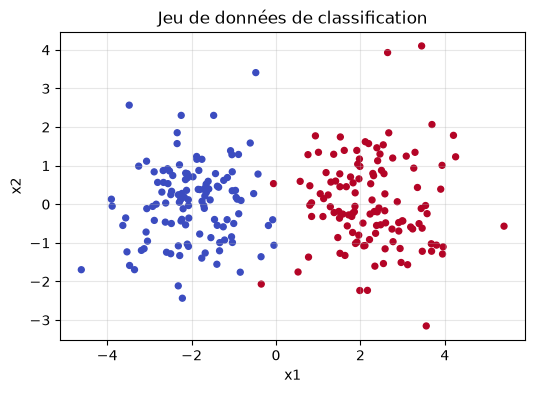

In [23]:
fixer_graine(0)
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long),
])
print("X_cls :", tuple(X_cls.shape), "| y_cls :", tuple(y_cls.shape), y_cls.dtype)

plt.figure(figsize=(6, 4))
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18, cmap="coolwarm")
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

X_cls = X_cls.to(device)
y_cls = y_cls.to(device)

## 16 et 17. Modèle et entraînement

Le réseau lit 2 coordonnées, passe par deux couches ReLU de 16 neurones et produit **2 logits**. La classe prédite sera `argmax(dim=1)`. On n'ajoute pas de softmax : `CrossEntropyLoss` le prend en charge. C'est une classification à deux classes avec deux scores, et non le cas `BCEWithLogitsLoss` à un seul logit vu plus haut.

Dernière perte : 0.0006943687913008034
Logits d'un exemple : shape du lot complet (240, 2)


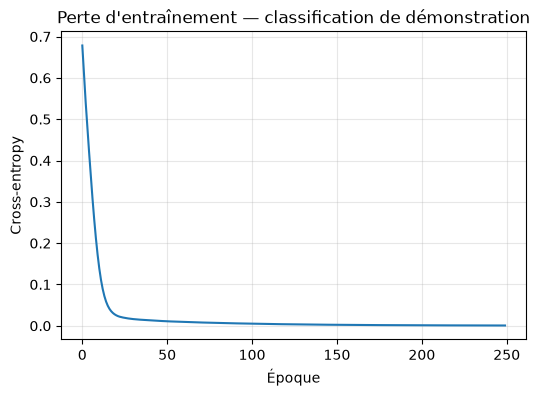

In [24]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2),
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier().to(device)
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

losses_cls = []
for epoch in range(250):
    model_cls.train()
    optimizer_cls.zero_grad()
    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)
    loss.backward()
    optimizer_cls.step()
    losses_cls.append(loss.item())

print("Dernière perte :", losses_cls[-1])
print("Logits d'un exemple : shape du lot complet", tuple(logits.shape))

plt.figure(figsize=(6, 4))
plt.plot(losses_cls)
plt.xlabel("Époque")
plt.ylabel("Cross-entropy")
plt.title("Perte d'entraînement — classification de démonstration")
plt.grid(True, alpha=0.3)
plt.show()

Le support importe `torcheval` et `torchmetrics`, avec `BinaryPrecision` écrit deux fois. Ces paquets ne sont pas nécessaires : accuracy, précision, rappel, F1 et matrice de confusion sont calculés avec scikit-learn, définitions équivalentes pour une classification binaire (classe positive = 1).

`argmax(dim=1)` réduit l'axe des 2 logits. Le résultat a la même forme que `y_cls`, `(240,)`, et peut être comparé terme à terme.

Accuracy  = 1.0000  (sur les 240 points d'entraînement)
Précision = 1.0000
Rappel    = 1.0000
F1-score  = 1.0000
Matrice de confusion (lignes = vraie classe, colonnes = prédiction) :
[[120   0]
 [  0 120]]
Effectif total de la matrice : 240
Ces quatre métriques portent sur les données d'entraînement de la démonstration.


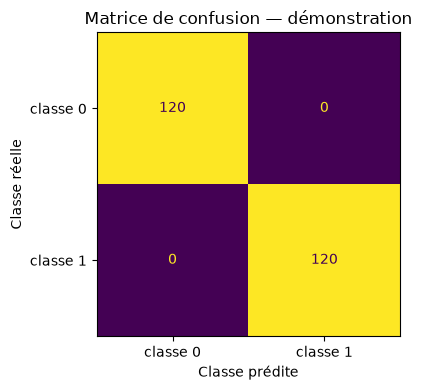

In [25]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)

model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)

y_np = y_cls.detach().cpu().numpy()
pred_np = pred.detach().cpu().numpy()
accuracy = accuracy_score(y_np, pred_np)
precision = precision_score(y_np, pred_np, average="binary", pos_label=1, zero_division=0)
recall = recall_score(y_np, pred_np, average="binary", pos_label=1, zero_division=0)
f1 = f1_score(y_np, pred_np, average="binary", pos_label=1, zero_division=0)
matrice = confusion_matrix(y_np, pred_np)

print(f"Accuracy  = {accuracy:.4f}  (sur les {len(y_np)} points d'entraînement)")
print(f"Précision = {precision:.4f}")
print(f"Rappel    = {recall:.4f}")
print(f"F1-score  = {f1:.4f}")
print("Matrice de confusion (lignes = vraie classe, colonnes = prédiction) :")
print(matrice)
print("Effectif total de la matrice :", int(matrice.sum()))
print("Ces quatre métriques portent sur les données d'entraînement de la démonstration.")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(
    matrice, display_labels=["classe 0", "classe 1"]
).plot(ax=ax, colorbar=False)
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title("Matrice de confusion — démonstration")
plt.tight_layout()
plt.show()

resultats["demo_classification"] = {
    "accuracy_entrainement": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1": float(f1),
    "effectif": int(matrice.sum()),
}

## Visualisation de la frontière de décision

On construit une grille de 200 × 200 points couvrant les données, avec une marge de 1. Le réseau classe chaque point de la grille. `contourf` colore les deux régions. La frontière affichée est celle du modèle **après** `eval()`, sans gradient.

Grille : (40000, 2) → 200 × 200 points, 2 coordonnées


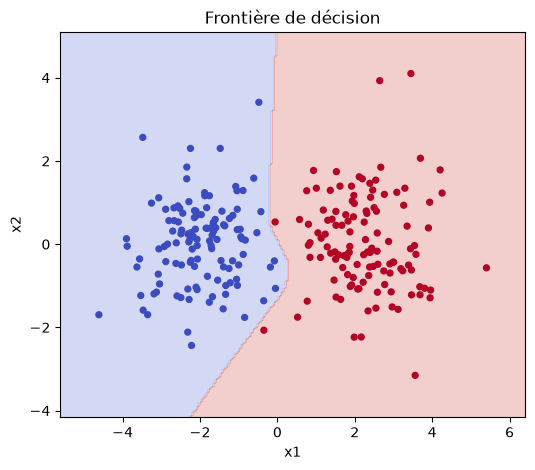

In [26]:
x_cpu = X_cls.detach().cpu()
x1_min, x1_max = x_cpu[:, 0].min() - 1, x_cpu[:, 0].max() + 1
x2_min, x2_max = x_cpu[:, 1].min() - 1, x_cpu[:, 1].max() + 1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing="ij",
)
grille = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1).to(device)
print("Grille :", tuple(grille.shape), "→ 200 × 200 points, 2 coordonnées")

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grille).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6, 5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.detach().cpu().numpy(), alpha=0.25, cmap="coolwarm")
plt.scatter(x_cpu[:, 0], x_cpu[:, 1], c=y_cls.detach().cpu(), s=18, cmap="coolwarm")
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

`state_dict` ne contient que les tenseurs de paramètres, pas le code de la classe. Il faut donc recréer un `Classifier` identique, puis y charger les poids. `map_location=device` permet de relire un fichier enregistré sur un autre appareil. La vérification compare les logits du modèle en mémoire et ceux du modèle rechargé, sur les mêmes points.

In [27]:
chemin = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), chemin)
print("Modèle sauvegardé dans", chemin)

modele_recharge = Classifier().to(device)
modele_recharge.load_state_dict(torch.load(chemin, map_location=device, weights_only=True))
modele_recharge.eval()
model_cls.eval()

with torch.inference_mode():
    logits_memoire = model_cls(X_cls)
    logits_relu = modele_recharge(X_cls)

memes_classes = torch.equal(logits_memoire.argmax(dim=1), logits_relu.argmax(dim=1))
memes_logits = torch.allclose(logits_memoire, logits_relu)
print("Prédictions de classe identiques :", bool(memes_classes))
print("Logits identiques :", bool(memes_logits))
assert memes_classes and memes_logits

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions de classe identiques : True
Logits identiques : True


# Synthèse de la démonstration

Les briques utilisées ensuite sont en place :

1. `Tensor`, formes et appareil ;
2. `autograd`, contrôlé sur $\partial L/\partial w = -12$ et $\partial L/\partial b = -6$ ;
3. `nn.Module`, `nn.Sequential` et `forward` ;
4. MSE, cross-entropy et BCE avec logits ;
5. `zero_grad`, `backward`, `step` ;
6. `train` / `eval`, distincts de `no_grad` et `inference_mode` ;
7. `TensorDataset` / `DataLoader` ;
8. sauvegarde par `state_dict`.

La régression synthétique ajuste une droite proche de $3x + 2$. La classification sépare les deux nuages et la frontière obtenue est cohérente avec leurs centres. Les scores de cette seconde démonstration, comme le $R^2$, décrivent l'ajustement aux données d'apprentissage.

# Partie 2 — Exercices

Ordre du sujet : salaires, Iris, MNIST avec un MLP, MNIST avec un CNN.

## Exercice 1 — Prédiction du salaire en DH

On construit une régression linéaire multiple du salaire mensuel à partir de deux variables :

- l'ancienneté, en années ;
- le niveau d'expertise, note de 1 à 5.

Le modèle apprend

$$
\text{salaire} = w_1 \times \text{ancienneté} + w_2 \times \text{expertise} + b.
$$

Les salaires sont en dirhams. Les 300 salariés sont fictifs.

### 1. Générer les données

La règle de simulation, bruit compris, est

$$
\text{salaire} = 4000 + 600 \times \text{ancienneté} + 1500 \times \text{expertise} + \text{bruit},
$$

où le bruit est gaussien, centré, d'écart-type 500 DH. La graine `torch.manual_seed(42)` rend le tirage reproductible. L'ancienneté est un entier de 0 à 20 inclus (`randint` s'arrête avant 21) et l'expertise un entier de 1 à 5.

In [28]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

n = 300
anciennete = torch.randint(0, 21, (n, 1)).float()
expertise = torch.randint(1, 6, (n, 1)).float()
bruit = torch.randn(n, 1) * 500

salaires = 4000 + 600 * anciennete + 1500 * expertise + bruit
X = torch.cat([anciennete, expertise], dim=1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé.** Afficher les dimensions de `X` et de `y`, le salaire moyen, puis le nuage du salaire selon l'ancienneté, avec une couleur par niveau d'expertise.

`X` empile les deux variables en colonnes : une ligne par salarié. `y` est un vecteur colonne `(300, 1)`, aligné sur la sortie d'un `nn.Linear(..., 1)`.

Dimensions de X : (300, 2)
Dimensions de y : (300, 1)
Salaire moyen : 15010.55 DH
Ancienneté de 0 à 20 ans ; expertise de 1 à 5


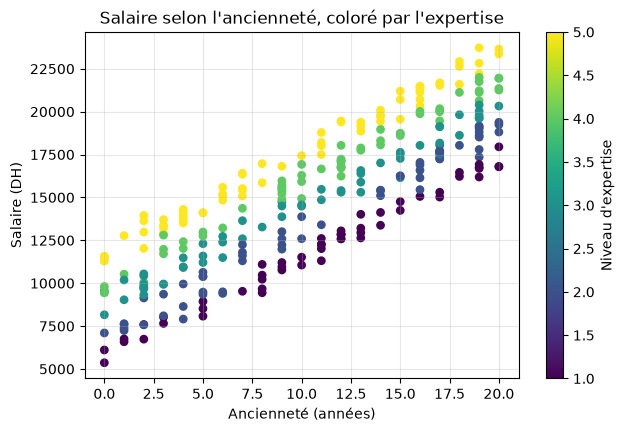

In [29]:
print("Dimensions de X :", tuple(X.shape))
print("Dimensions de y :", tuple(y.shape))
print(f"Salaire moyen : {y.mean().item():.2f} DH")
print(
    f"Ancienneté de {X[:, 0].min().item():.0f} à {X[:, 0].max().item():.0f} ans ; "
    f"expertise de {X[:, 1].min().item():.0f} à {X[:, 1].max().item():.0f}"
)

fig, ax = plt.subplots(figsize=(7, 4.5))
nuage = ax.scatter(
    X[:, 0].numpy(),
    y[:, 0].numpy(),
    c=X[:, 1].numpy(),
    cmap="viridis",
    s=28,
)
barre = fig.colorbar(nuage, ax=ax)
barre.set_label("Niveau d'expertise")
ax.set_xlabel("Ancienneté (années)")
ax.set_ylabel("Salaire (DH)")
ax.set_title("Salaire selon l'ancienneté, coloré par l'expertise")
ax.grid(True, alpha=0.3)
plt.show()

Le nuage monte avec l'ancienneté. À ancienneté comparable, les points d'expertise élevée (couleurs claires de l'échelle) se situent plus haut : les deux variables tirent le salaire, avant même l'apprentissage.

### 2. Séparer et préparer les données

80 % des salariés servent à l'entraînement (240) et 20 % au test (60). Le tirage `randperm` prolonge la graine fixée avant la génération : il ne faut pas relancer `manual_seed` entre les deux cellules.

Deux préparations aident SGD :

- standardiser les entrées avec la **moyenne et l'écart-type du seul jeu d'entraînement**, puis réutiliser ces deux statistiques pour le test et pour toute nouvelle observation ;
- exprimer la cible en milliers de DH, afin que la perte et le pas `0.05` vivent sur une échelle de quelques unités, et non en milliers de dirhams.

`Tensor.std` est ici l'écart-type non biaisé (division par $n - 1$), comme dans le support. Le même choix est conservé partout.

In [30]:
indices = torch.randperm(n)
limite = int(0.8 * n)
train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)
X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

print("Entraînement :", tuple(X_train_norm.shape), tuple(y_train.shape))
print("Test         :", tuple(X_test_norm.shape), tuple(y_test.shape))
print("Moyenne (ancienneté, expertise) :", moyenne.view(-1).tolist())
print("Écart-type (ancienneté, expertise) :", ecart_type.view(-1).tolist())
print(f"Cible d'entraînement, moyenne en milliers de DH : {y_train.mean().item():.3f}")

X_train_norm = X_train_norm.to(device)
X_test_norm = X_test_norm.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)
moyenne = moyenne.to(device)
ecart_type = ecart_type.to(device)

Entraînement : (240, 2) (240, 1)
Test         : (60, 2) (60, 1)
Moyenne (ancienneté, expertise) : [10.537500381469727, 3.1541666984558105]
Écart-type (ancienneté, expertise) : [6.12275505065918, 1.4395719766616821]
Cible d'entraînement, moyenne en milliers de DH : 15.038


### 3. Construire et entraîner le modèle

`nn.Linear(2, 1)` est le modèle demandé : deux variables, un salaire. La perte est `MSELoss`. L'optimiseur est SGD avec un taux de 0,05, pendant 500 époques. Chaque époque voit les 240 salariés d'un coup (pas de mini-lots dans cet exercice).

Après standardisation, un poids n'est plus « des DH par année ». Le retour aux unités d'origine est fait plus bas, une fois l'apprentissage terminé.

In [31]:
model = nn.Linear(2, 1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

historique = []
model.train()
for epoch in range(500):
    optimizer.zero_grad()
    predictions = model(X_train_norm)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()
    historique.append(loss.item())
    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")

print("Forme des prédictions d'entraînement :", tuple(predictions.shape))

Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391


Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391
Forme des prédictions d'entraînement : (240, 1)


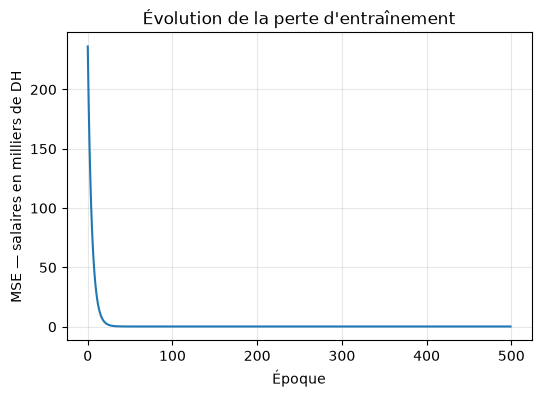

In [32]:
plt.figure(figsize=(6, 4))
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid(True, alpha=0.3)
plt.show()

La perte descend vite puis se stabilise au-dessus de zéro. Le palier est le point utile : il sera comparé à la variance du bruit, pas à une erreur d'implémentation.

### 4. Évaluer les prédictions

Le modèle passe en `eval()`. `torch.no_grad()` bloque le graphe : on ne met plus les poids à jour. Les prédictions et les cibles, apprises en milliers de DH, sont multipliées par 1000 avant la MAE. Cette MAE est celle du **jeu de test**.

In [33]:
model.eval()
with torch.no_grad():
    predictions_test = model(X_test_norm)
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000
    mae = (predictions_dh - salaires_reels_dh).abs().mean()

print(f"Erreur absolue moyenne sur le test : {mae.item():.2f} DH")
print("Une MAE de 400 DH signifierait un écart moyen de 400 DH entre prédiction et salaire réel.")
mae_bruit = 500 * math.sqrt(2 / math.pi)
print(f"MAE théorique du seul bruit gaussien (sigma = 500) : {mae_bruit:.2f} DH")
print(f"Perte d'entraînement finale : {historique[-1]:.4f}")
print(f"Variance du bruit en milliers de DH au carré : {(500 / 1000) ** 2:.4f}")

Erreur absolue moyenne sur le test : 381.64 DH
Une MAE de 400 DH signifierait un écart moyen de 400 DH entre prédiction et salaire réel.
MAE théorique du seul bruit gaussien (sigma = 500) : 398.94 DH
Perte d'entraînement finale : 0.2391
Variance du bruit en milliers de DH au carré : 0.2500


### 5. Prédire le salaire d'un nouveau salarié

La personne a 7 ans d'ancienneté et une expertise de 4/5. On lui applique **la moyenne et l'écart-type de l'entraînement**, puis on reconvertit la sortie en DH.

Sans bruit, la règle de génération donne

$$
4000 + 600 \times 7 + 1500 \times 4 = 14200\ \text{DH}.
$$

### Coefficients dans les unités d'origine

Le réseau apprend $y_{\text{milliers}} = w_1 z_1 + w_2 z_2 + b$ avec $z_j = (x_j - m_j) / s_j$. En dirhams :

$$
\text{salaire} = 1000\left(b - \sum_j w_j \frac{m_j}{s_j}\right) + \sum_j \left(1000 \frac{w_j}{s_j}\right) x_j.
$$

Le terme en ancienneté est l'effet d'une année supplémentaire à expertise constante. Cette inversion annule à la fois la standardisation et le passage en milliers de DH.

In [34]:
nouveau_salarie = torch.tensor([[7.0, 4.0]], device=device)
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

salaire_dh = salaire_predit.item()
print(f"Salaire estimé (7 ans, expertise 4) : {salaire_dh:.2f} DH")
print("Valeur théorique sans bruit : 14200 DH")
print(f"Écart à 14 200 DH : {salaire_dh - 14200:.2f} DH")

anciennete_40 = torch.tensor([[40.0, 4.0]], device=device)
anciennete_40_norm = (anciennete_40 - moyenne) / ecart_type
with torch.no_grad():
    salaire_40 = (model(anciennete_40_norm) * 1000).item()
theorique_40 = 4000 + 600 * 40 + 1500 * 4
print(f"Ancienneté observée à l'entraînement : {X_train[:, 0].min().item():.0f} à {X_train[:, 0].max().item():.0f} ans")
print(f"Prédiction à 40 ans et expertise 4 : {salaire_40:.2f} DH")
print(f"Prolongement arithmétique de la règle sans bruit : {theorique_40:.0f} DH")

poids = model.weight.detach().view(-1).cpu()
biais = model.bias.detach().view(-1).cpu()[0]
m = moyenne.detach().view(-1).cpu()
s = ecart_type.detach().view(-1).cpu()
coef = 1000 * poids / s
ordonnee = 1000 * (biais - torch.sum(poids * m / s))

print(f"Coefficient ancienneté : {coef[0].item():.2f} DH par an")
print(f"Coefficient expertise  : {coef[1].item():.2f} DH par niveau")
print(f"Ordonnée à l'origine   : {ordonnee.item():.2f} DH")
print("Valeurs de simulation     : 600 DH/an, 1500 DH/niveau, 4000 DH")

resultats["salaire"] = {
    "mae_test_dh": float(mae.item()),
    "prediction_7_4": float(salaire_dh),
    "ecart_14200": float(salaire_dh - 14200),
    "prediction_40_4": float(salaire_40),
    "coef_anciennete": float(coef[0].item()),
    "coef_expertise": float(coef[1].item()),
    "ordonnee": float(ordonnee.item()),
    "perte_finale": float(historique[-1]),
    "anciennete_min": float(X_train[:, 0].min().item()),
    "anciennete_max": float(X_train[:, 0].max().item()),
}

Salaire estimé (7 ans, expertise 4) : 14201.94 DH
Valeur théorique sans bruit : 14200 DH
Écart à 14 200 DH : 1.94 DH
Ancienneté observée à l'entraînement : 0 à 20 ans
Prédiction à 40 ans et expertise 4 : 33759.86 DH
Prolongement arithmétique de la règle sans bruit : 34000 DH
Coefficient ancienneté : 592.66 DH par an
Coefficient expertise  : 1490.75 DH par niveau
Ordonnée à l'origine   : 4090.30 DH
Valeurs de simulation     : 600 DH/an, 1500 DH/niveau, 4000 DH


### Effet d'un bruit plus fort

Pour répondre avec une mesure, et non seulement avec le raisonnement, la même procédure est rejouée deux fois : même graine, mêmes étapes, seul l'écart-type du bruit change (500 DH, puis 1 500 DH). Un générateur local évite de modifier les tenseurs de l'exercice principal. Cette comparaison est donc une expérience contrôlée à part.

In [35]:
def mae_selon_bruit(ecart_bruit, graine=42):
    # Rejoue l'exercice 1 avec un autre écart-type de bruit. Retourne la MAE de test en DH.
    generateur = torch.Generator().manual_seed(graine)
    effectif = 300
    anc = torch.randint(0, 21, (effectif, 1), generator=generateur).float()
    exp = torch.randint(1, 6, (effectif, 1), generator=generateur).float()
    perturbation = torch.randn(effectif, 1, generator=generateur) * ecart_bruit
    entrees = torch.cat([anc, exp], dim=1)
    cibles = 4000 + 600 * anc + 1500 * exp + perturbation

    ordre = torch.randperm(effectif, generator=generateur)
    coupe = int(0.8 * effectif)
    ent_app, ent_test = entrees[ordre[:coupe]], entrees[ordre[coupe:]]
    cib_app = cibles[ordre[:coupe]] / 1000
    cib_test = cibles[ordre[coupe:]] / 1000
    mu = ent_app.mean(dim=0, keepdim=True)
    sigma = ent_app.std(dim=0, keepdim=True)

    reseau = nn.Linear(2, 1)
    optimiseur = torch.optim.SGD(reseau.parameters(), lr=0.05)
    perte_mse = nn.MSELoss()
    reseau.train()
    for _ in range(500):
        optimiseur.zero_grad()
        perte = perte_mse(reseau((ent_app - mu) / sigma), cib_app)
        perte.backward()
        optimiseur.step()

    reseau.eval()
    with torch.no_grad():
        prevu = reseau((ent_test - mu) / sigma) * 1000
        reel = cib_test * 1000
        return (prevu - reel).abs().mean().item()

mae_500 = mae_selon_bruit(500)
mae_1500 = mae_selon_bruit(1500)
print(f"Expérience contrôlée, MAE de test, bruit  500 DH : {mae_500:.2f} DH")
print(f"Expérience contrôlée, MAE de test, bruit 1500 DH : {mae_1500:.2f} DH")
print(f"Rapport des MAE : {mae_1500 / mae_500:.2f} (le bruit a été multiplié par 3)")
resultats["salaire"]["mae_bruit_500"] = float(mae_500)
resultats["salaire"]["mae_bruit_1500"] = float(mae_1500)

Expérience contrôlée, MAE de test, bruit  500 DH : 381.64 DH
Expérience contrôlée, MAE de test, bruit 1500 DH : 1144.93 DH
Rapport des MAE : 3.00 (le bruit a été multiplié par 3)


### Réponses — exercice 1

Les valeurs numériques sont celles imprimées par les cellules précédentes. La lecture à en faire est la suivante.

**Effet d'une année d'ancienneté, à expertise constante.** C'est le coefficient d'ancienneté ramené en DH par an. Il doit avoisiner 600, le coefficient de la simulation. L'expertise constante est déjà l'hypothèse du modèle linéaire : on ajoute 1 à l'ancienneté sans changer l'autre variable, et la prédiction augmente de ce coefficient.

**Pourquoi la perte ne devient-elle pas nulle ?** Le salaire observé contient un bruit d'écart-type 500 DH, soit 0,5 millier de DH. La variance de ce bruit vaut 0,25 dans l'unité de la perte. Une droite, même parfaite, ne peut pas prédire la part aléatoire. La perte finale se stabilise donc près de cette variance, et la MAE de test se situe près de l'écart absolu moyen d'une loi normale de paramètre 500, soit $500\sqrt{2/\pi} \approx 399$ DH. Le palier n'est pas un entraînement trop court.

**Ancienneté de 40 ans.** Les données d'entraînement restent dans 0–20 ans. La prédiction à 40 ans prolonge la droite apprise et peut retomber près de $4000 + 600\times 40 + 1500\times 4 = 34000$ DH, mais aucun salarié observé ne valide cette zone. Le modèle est une extrapolation : il est arithmétiquement défini, il n'est pas fiable hors du domaine vu.

**Si le bruit augmente.** L'expérience contrôlée multiplie l'écart-type par trois, de 500 à 1 500 DH, et la MAE de test augmente dans une proportion voisine. La précision se dégrade : une part plus grande du salaire échappe aux deux variables, et les coefficients sont estimés avec plus de variance.

**Coefficients d'origine.** Après annulation de la standardisation et de la conversion en milliers de DH, les trois paramètres retrouvent l'ordre de grandeur de 600, 1 500 et 4 000. L'écart résiduel vient du bruit et du fait que l'écart-type utilisé est celui, non biaisé, du seul échantillon d'entraînement.

## Exercice 2 — Classification des fleurs Iris

Objectif : prédire l'espèce d'une fleur à partir de quatre mesures

- longueur et largeur des sépales ;
- longueur et largeur des pétales.

Le jeu Iris contient 150 fleurs et trois classes : setosa, versicolor et virginica. Bibliothèques utilisées : PyTorch et scikit-learn.

Dans le support, ce titre arrivait après le code et portait le numéro 3, tandis que le MLP MNIST portait le numéro 2. L'ordre retenu ici est celui de l'énoncé : Iris est l'exercice 2, le MLP l'exercice 3.

### 1. Préparation des données

Découpage 80 % / 20 %, stratifié, `random_state=42`. `StandardScaler` est ajusté sur l'entraînement seul, puis appliqué au test. Les entrées sont en `float32`, les étiquettes en `torch.long`.

In [36]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

iris = load_iris()
X_iris_np, y_iris_np = iris.data, iris.target
print("Noms des mesures :", list(iris.feature_names))
print("Noms des espèces :", list(iris.target_names))
print("Forme brute :", X_iris_np.shape, y_iris_np.shape)

X_app, X_eval, y_app, y_eval = train_test_split(
    X_iris_np,
    y_iris_np,
    test_size=0.2,
    random_state=42,
    stratify=y_iris_np,
)

scaler = StandardScaler()
X_app = scaler.fit_transform(X_app)
X_eval = scaler.transform(X_eval)

X_train = torch.tensor(X_app, dtype=torch.float32, device=device)
X_test = torch.tensor(X_eval, dtype=torch.float32, device=device)
y_train = torch.tensor(y_app, dtype=torch.long, device=device)
y_test = torch.tensor(y_eval, dtype=torch.long, device=device)

print("Dimensions :", tuple(X_train.shape), tuple(y_train.shape))
print("Test :", tuple(X_test.shape), tuple(y_test.shape), "| dtype étiquettes :", y_train.dtype)
print("Effectifs par classe, entraînement :", torch.bincount(y_train.cpu()).tolist())
print("Effectifs par classe, test :", torch.bincount(y_test.cpu()).tolist())

Noms des mesures : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Noms des espèces : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Forme brute : (150, 4) (150,)
Dimensions : (120, 4) (120,)
Test : (30, 4) (30,) | dtype étiquettes : torch.int64
Effectifs par classe, entraînement : [40, 40, 40]
Effectifs par classe, test : [10, 10, 10]


### Réponses — préparation

**Que représentent les quatre colonnes ?** Ce sont, dans l'ordre imprimé ci-dessus, la longueur du sépale, la largeur du sépale, la longueur du pétale et la largeur du pétale, en centimètres. Chaque ligne est une fleur. Après `StandardScaler`, les colonnes n'ont plus cette unité : elles sont centrées et réduites avec les statistiques d'entraînement.

**Pourquoi `torch.long` ?** `CrossEntropyLoss` attend l'indice de la classe, un entier 64 bits (`torch.long`), ici 0, 1 ou 2. Un flottant serait refusé. Un vecteur one-hot serait aussi la mauvaise cible pour cette fonction de perte : l'indice suffit, le `log_softmax` est interne.

**Pourquoi ne pas ajuster le scaler sur le test ?** `fit` sur le test ferait entrer la moyenne et l'écart-type du jeu d'évaluation dans la préparation. Ce serait une fuite de données : le score mesurerait en partie une transformation qui a déjà « vu » les fleurs à prédire, et il surestimerait la généralisation. On ajuste sur l'entraînement, on fige ces statistiques, et le test n'est que transformé. C'est le même principe que la moyenne et l'écart-type de l'exercice 1.

### 2. Construire le réseau

Le squelette laisse la largeur cachée libre. **16 neurones** suffisent pour 4 mesures et 3 classes : la couche peut représenter une recombinaison non linéaire des mesures sans empiler de paramètres inutiles sur 120 fleurs. La sortie a 3 logits, un par espèce.

Aucun `Softmax` n'est ajouté. `CrossEntropyLoss` attend les scores bruts.

In [37]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3),
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
print(model)
print("Appareil :", next(model.parameters()).device)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)
Appareil : cpu


### 3. Entraîner le modèle

Chaque époque utilise les 120 fleurs d'entraînement d'un seul coup, pendant 200 époques. Adam a un pas de 0,01. Les logits vont directement à la cross-entropy.

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063


Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525


Époque 140 | Perte : 0.0488

Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445


Époque 200 | Perte : 0.0432
Logits d'entraînement : (120, 3) → (120 fleurs, 3 espèces)


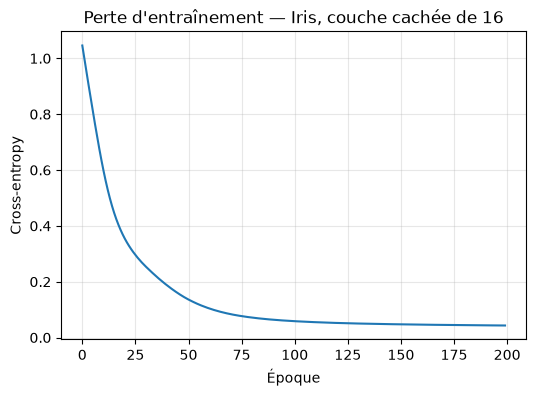

In [38]:
epochs = 200
losses = []
model.train()

for epoch in range(epochs):
    optimizer.zero_grad()
    logits = model(X_train)
    loss = criterion(logits, y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

print("Logits d'entraînement :", tuple(logits.shape), "→ (120 fleurs, 3 espèces)")

plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Cross-entropy")
plt.title("Perte d'entraînement — Iris, couche cachée de 16")
plt.grid(True, alpha=0.3)
plt.show()

### 4. Évaluer le classifieur

`argmax(dim=1)` choisit, pour chaque fleur, l'espèce au logit le plus élevé. L'accuracy est la proportion de bonnes décisions sur les **30 fleurs de test** (20 % de 150, stratification 10 / 10 / 10). La matrice doit totaliser 30.

Accuracy sur le test : 100.0%
Prédictions : (30,) | logits : (30, 3)


[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
Exemples comptés dans la matrice : 30


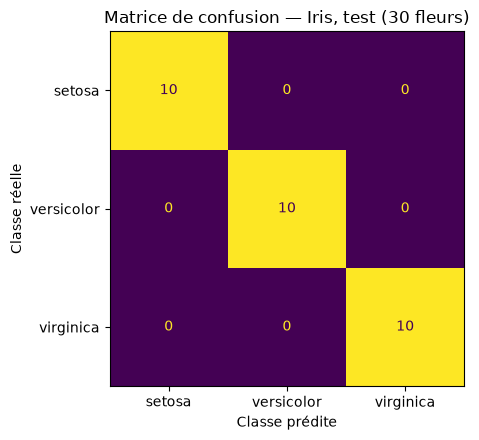

In [39]:
noms_iris = ["setosa", "versicolor", "virginica"]

model.eval()
with torch.no_grad():
    logits = model(X_test)
    predictions = logits.argmax(dim=1)
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")
print("Prédictions :", tuple(predictions.shape), "| logits :", tuple(logits.shape))

y_test_np = y_test.detach().cpu().numpy()
pred_iris = predictions.detach().cpu().numpy()
matrice_iris = confusion_matrix(y_test_np, pred_iris)
print(matrice_iris)
print("Exemples comptés dans la matrice :", int(matrice_iris.sum()))
assert matrice_iris.sum() == 30

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(matrice_iris, display_labels=noms_iris).plot(ax=ax, colorbar=False)
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title("Matrice de confusion — Iris, test (30 fleurs)")
plt.tight_layout()
plt.show()

resultats["iris"] = {
    "accuracy": float(accuracy.item()),
    "somme_matrice": int(matrice_iris.sum()),
}

### 5. Comparaison linéaire et nouvelle fleur

Le protocole du réseau à couche cachée est rejoué avec `nn.Linear(4, 3)` : mêmes tenseurs déjà préparés, 200 époques, Adam à 0,01, cross-entropy, batch complet. Ce modèle est une régression logistique multinomiale, sans ReLU.

La nouvelle fleur `[5.1, 3.5, 1.4, 0.2]` est transformée avec le scaler **déjà ajusté**, puis présentée au réseau à couche cachée. Le softmax n'est calculé qu'après coup, pour lire des probabilités ; il n'entre pas dans la perte.

Accuracy du réseau 4 → 16 → 3 : 100.0%
Accuracy de nn.Linear(4, 3)     : 90.0%
Écart (réseau − linéaire)        : +10.0%
Matrice du modèle linéaire, total : 30
[[10  0  0]
 [ 0  8  2]
 [ 0  1  9]]


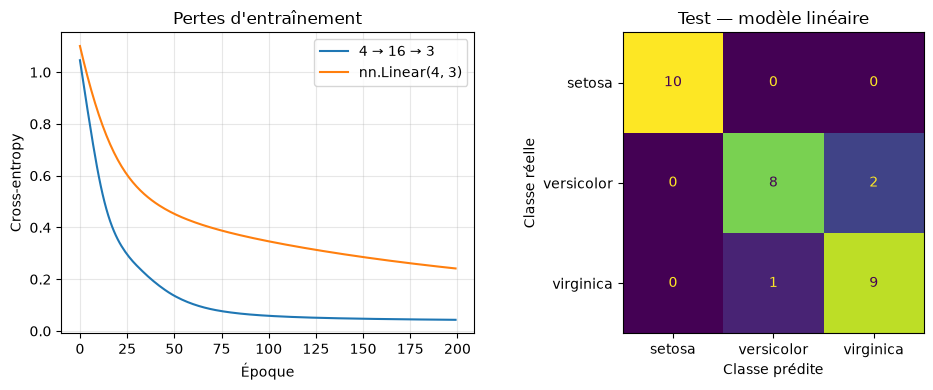

Mesures brutes : [5.1, 3.5, 1.4, 0.2]
Après le scaler d'entraînement : [-0.886, 1.011, -1.346, -1.323]
Logits du réseau : [5.683, -3.26, -8.998]
Probabilités lues après coup : {'setosa': 1.0, 'versicolor': 0.0, 'virginica': 0.0}
Espèce prédite par le réseau : setosa
Espèce prédite par le modèle linéaire : setosa


In [40]:
torch.manual_seed(42)
modele_lineaire = nn.Linear(4, 3).to(device)
optimiseur_lineaire = torch.optim.Adam(modele_lineaire.parameters(), lr=0.01)
perte_lineaire = nn.CrossEntropyLoss()
historique_lineaire = []

modele_lineaire.train()
for epoch in range(200):
    optimiseur_lineaire.zero_grad()
    logits_lin = modele_lineaire(X_train)
    perte = perte_lineaire(logits_lin, y_train)
    perte.backward()
    optimiseur_lineaire.step()
    historique_lineaire.append(perte.item())

modele_lineaire.eval()
with torch.no_grad():
    pred_lineaire = modele_lineaire(X_test).argmax(dim=1)
accuracy_lineaire = (pred_lineaire == y_test).float().mean().item()
matrice_lineaire = confusion_matrix(y_test_np, pred_lineaire.detach().cpu().numpy())

print(f"Accuracy du réseau 4 → 16 → 3 : {resultats['iris']['accuracy']:.1%}")
print(f"Accuracy de nn.Linear(4, 3)     : {accuracy_lineaire:.1%}")
print(f"Écart (réseau − linéaire)        : {resultats['iris']['accuracy'] - accuracy_lineaire:+.1%}")
print("Matrice du modèle linéaire, total :", int(matrice_lineaire.sum()))
print(matrice_lineaire)
assert matrice_lineaire.sum() == 30

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(losses, label="4 → 16 → 3")
axes[0].plot(historique_lineaire, label="nn.Linear(4, 3)")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Cross-entropy")
axes[0].set_title("Pertes d'entraînement")
axes[0].grid(True, alpha=0.3)
axes[0].legend()
ConfusionMatrixDisplay(matrice_lineaire, display_labels=noms_iris).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Test — modèle linéaire")
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Classe réelle")
plt.tight_layout()
plt.show()

mesures = [[5.1, 3.5, 1.4, 0.2]]
mesures_norm = scaler.transform(mesures)
fleur = torch.tensor(mesures_norm, dtype=torch.float32, device=device)

model.eval()
with torch.no_grad():
    logits_fleur = model(fleur)
    proba_fleur = torch.softmax(logits_fleur, dim=1)
    espece = int(logits_fleur.argmax(dim=1).item())
    logits_fleur_lin = modele_lineaire(fleur)
    espece_lin = int(logits_fleur_lin.argmax(dim=1).item())

print("Mesures brutes :", mesures[0])
print("Après le scaler d'entraînement :", [round(v, 3) for v in mesures_norm[0].tolist()])
print("Logits du réseau :", [round(v, 3) for v in logits_fleur.view(-1).tolist()])
print(
    "Probabilités lues après coup :",
    {nom: round(p, 3) for nom, p in zip(noms_iris, proba_fleur.view(-1).tolist())},
)
print(f"Espèce prédite par le réseau : {noms_iris[espece]}")
print(f"Espèce prédite par le modèle linéaire : {noms_iris[espece_lin]}")

resultats["iris"]["accuracy_lineaire"] = float(accuracy_lineaire)
resultats["iris"]["espece_reseau"] = noms_iris[espece]
resultats["iris"]["espece_lineaire"] = noms_iris[espece_lin]

### Lecture des scores Iris

Setosa se sépare des deux autres espèces par des pétales courts. Versicolor et virginica se recouvrent davantage. Sur 30 fleurs de test, une fleur représente environ 3,3 points d'accuracy.

La cellule précédente mesure les deux protocoles sur le même découpage. Le réseau 4 → 16 → 3 classe les 30 fleurs (accuracy 100 %, matrice diagonale 10 / 10 / 10). `nn.Linear(4, 3)` atteint 90 % : setosa reste parfaite (10/10), et les trois erreurs sont entre versicolor et virginica (2 versicolor prédits virginica, 1 virginica prédite versicolor). Sur ce découpage, la couche ReLU et ses 16 neurones améliorent donc le test de trois fleurs. L'écart ne dit pas qu'Iris exigerait un grand réseau : il dit que la frontière linéaire rate une partie du chevauchement versicolor / virginica.

La fleur `[5.1, 3.5, 1.4, 0.2]` a des pétales courts, le profil de setosa. Les deux modèles la prédisent setosa, après la transformation du scaler d'entraînement. Le softmax affiché n'a pas servi à l'apprentissage.

## Exercice 3 — Classification MNIST avec un MLP

Objectif : enchaîner des mini-lots et évaluer sur le jeu de test officiel.

MNIST compte 60 000 images d'entraînement et 10 000 images de test, chiffres manuscrits de 0 à 9, en niveaux de gris, 28 × 28. `ToTensor()` passe les pixels dans $[0, 1]$ et produit un canal : forme `(1, 28, 28)` par image.

Les chargeurs suivent l'énoncé : lot de 64 et `shuffle=True` pour l'entraînement, lot de 256 et `shuffle=False` pour le test, avec `num_workers=0`.

In [41]:
from torchvision import datasets, transforms
import torchvision

print("torchvision :", torchvision.__version__)

transform_mlp = transforms.ToTensor()
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform_mlp)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform_mlp)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS
)
print("Entraînement :", len(train_dataset), "images | Test :", len(test_dataset), "images")
print("Lots d'entraînement :", len(train_loader), "| Lots de test :", len(test_loader))

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

def construire_mlp():
    # MLP du sujet : Flatten, Linear(784, 128), ReLU, Linear(128, 10).
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    ).to(device)

model = construire_mlp()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

torchvision : 0.29.2+cpu
Entraînement : 60000 images | Test : 10000 images
Lots d'entraînement : 938 | Lots de test : 40
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Paramètres : 101770


`Flatten` transforme chaque image `(1, 28, 28)` en un vecteur de $28 \times 28 = 784$ valeurs. Le MLP traite donc les pixels comme 784 variables indépendantes de leur voisinage. La sortie a 10 logits. Pas de softmax : la cross-entropy reçoit ces logits, et les étiquettes sont des entiers de 0 à 9.

### Entraînement — 5 époques

`CrossEntropyLoss` renvoie la moyenne du lot. Le dernier lot d'une époque est incomplet (60 000 n'est pas divisible par 64). Multiplier `loss.item()` par `images.size(0)` puis diviser par l'effectif total donne la perte moyenne **par image**, et non une moyenne naïve des moyennes de lots.

Époque 1/5 | Perte moyenne : 0.3401


Époque 2/5 | Perte moyenne : 0.1556


Époque 3/5 | Perte moyenne : 0.1091


Époque 4/5 | Perte moyenne : 0.0828


Époque 5/5 | Perte moyenne : 0.0649


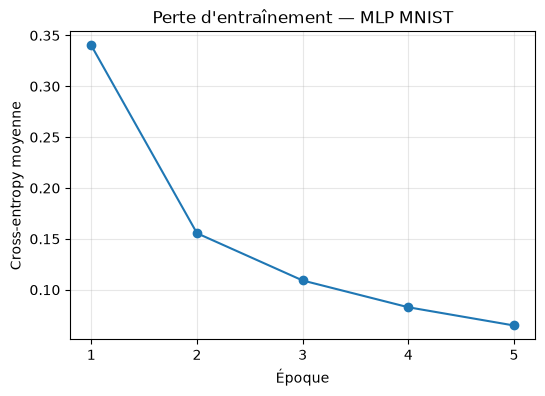

In [42]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

epochs = 5
historique_mlp = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    total_exemples = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        total_exemples += images.size(0)
    perte_moyenne = total_loss / total_exemples
    historique_mlp.append(perte_moyenne)
    print(f"Époque {epoch + 1}/{epochs} | Perte moyenne : {perte_moyenne:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), historique_mlp, marker="o")
plt.xlabel("Époque")
plt.ylabel("Cross-entropy moyenne")
plt.title("Perte d'entraînement — MLP MNIST")
plt.xticks(range(1, epochs + 1))
plt.grid(True, alpha=0.3)
plt.show()

### Évaluation sur les 10 000 images de test

`model.eval()` et `torch.no_grad()` sont utilisés ensemble. `argmax(dim=1)` fournit la classe prédite. Accuracy, précision, rappel et F1 sont des moyennes **macro** : chaque métrique est d'abord calculée pour chacun des dix chiffres, puis les dix valeurs sont moyennées avec le même poids. Une classe rare pèserait autant qu'une classe fréquente. Sur MNIST les effectifs sont presque équilibrés, donc la moyenne macro reste proche d'une moyenne pondérée, mais ce n'est pas la définition utilisée ici.

La matrice de confusion doit totaliser 10 000.

Images évaluées : 10000
Accuracy        : 97.41%
Précision macro : 97.41%
Rappel macro    : 97.40%
F1-score macro  : 97.40%
Somme de la matrice de confusion : 10000


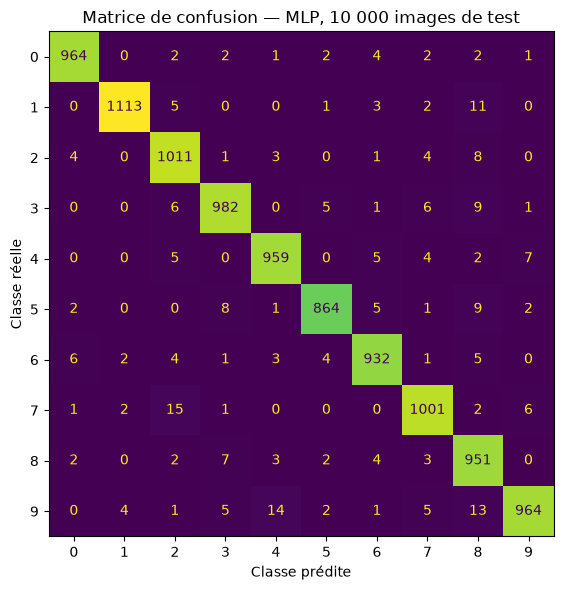

Erreurs affichées : 8 (plusieurs cas, pas l'ensemble des erreurs)


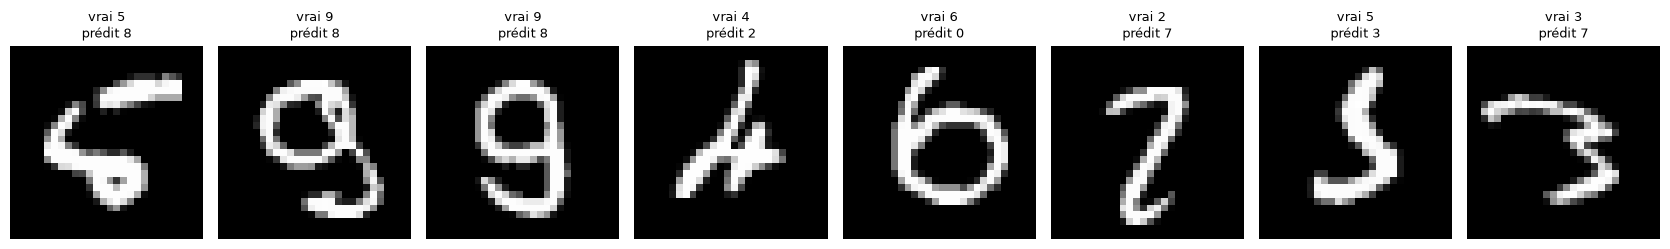

In [43]:
model.eval()
tous_pred = []
tous_vrais = []
erreurs_mlp = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        predicted_classes = outputs.argmax(dim=1)
        tous_pred.append(predicted_classes.cpu())
        tous_vrais.append(labels.cpu())
        mauvais = predicted_classes.cpu() != labels.cpu()
        for image, vrai, prevu in zip(images.cpu()[mauvais], labels.cpu()[mauvais], predicted_classes.cpu()[mauvais]):
            if len(erreurs_mlp) < 8:
                erreurs_mlp.append((image, int(vrai), int(prevu)))

y_vrais = torch.cat(tous_vrais).numpy()
y_prevus = torch.cat(tous_pred).numpy()

acc_mlp = accuracy_score(y_vrais, y_prevus)
prec_mlp = precision_score(y_vrais, y_prevus, average="macro", zero_division=0)
rec_mlp = recall_score(y_vrais, y_prevus, average="macro", zero_division=0)
f1_mlp = f1_score(y_vrais, y_prevus, average="macro", zero_division=0)
matrice_mlp = confusion_matrix(y_vrais, y_prevus)

print(f"Images évaluées : {len(y_vrais)}")
print(f"Accuracy        : {acc_mlp:.2%}")
print(f"Précision macro : {prec_mlp:.2%}")
print(f"Rappel macro    : {rec_mlp:.2%}")
print(f"F1-score macro  : {f1_mlp:.2%}")
print("Somme de la matrice de confusion :", int(matrice_mlp.sum()))
assert len(y_vrais) == 10000
assert matrice_mlp.sum() == 10000

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matrice_mlp).plot(ax=ax, colorbar=False)
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title("Matrice de confusion — MLP, 10 000 images de test")
plt.tight_layout()
plt.show()

print(f"Erreurs affichées : {len(erreurs_mlp)} (plusieurs cas, pas l'ensemble des erreurs)")
colonnes = len(erreurs_mlp)
fig, axes = plt.subplots(1, colonnes, figsize=(2.1 * colonnes, 2.6))
if colonnes == 1:
    axes = [axes]
for ax, (image, vrai, prevu) in zip(axes, erreurs_mlp):
    ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"vrai {vrai}\nprédit {prevu}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

resultats["mlp"] = {
    "accuracy": float(acc_mlp),
    "precision": float(prec_mlp),
    "recall": float(rec_mlp),
    "f1": float(f1_mlp),
    "somme_matrice": int(matrice_mlp.sum()),
    "n_test": int(len(y_vrais)),
    "epochs": 5,
    "perte_finale": float(historique_mlp[-1]),
    "parametres": int(sum(p.numel() for p in model.parameters())),
}

Les confusions se concentrent en pratique sur des chiffres de forme voisine (par exemple 4/9, 3/5, 7/9). Les vignettes montrent la vraie classe et la décision du MLP. Les pixels affichés sont ceux de `ToTensor()`, déjà dans $[0, 1]$ : cet exercice ne normalise pas davantage.

### Sauvegarder et recharger

Les poids vont dans `mnist_mlp.pth`. Un réseau neuf, de la même architecture, est créé puis chargé. Avant le chargement, ses prédictions sur un lot réel du test diffèrent de celles du modèle entraîné. Après le chargement, les logits coïncident, sans nouvel apprentissage.

In [44]:
chemin_mlp = "mnist_mlp.pth"
torch.save(model.state_dict(), chemin_mlp)
print("Paramètres enregistrés dans", chemin_mlp)

modele_neuf = construire_mlp()
lot_images, lot_labels = next(iter(test_loader))
lot_images = lot_images.to(device)
print("Lot réel utilisé pour le contrôle :", tuple(lot_images.shape), "| étiquettes :", tuple(lot_labels.shape))

model.eval()
modele_neuf.eval()
with torch.no_grad():
    logits_entraine = model(lot_images)
    logits_neuf = modele_neuf(lot_images)
avant = torch.equal(logits_entraine.argmax(dim=1), logits_neuf.argmax(dim=1))
print("Avant chargement, classes identiques sur ce lot :", bool(avant))

modele_neuf.load_state_dict(torch.load(chemin_mlp, map_location=device, weights_only=True))
modele_neuf.eval()
with torch.no_grad():
    logits_relu = modele_neuf(lot_images)
apres_classes = torch.equal(logits_entraine.argmax(dim=1), logits_relu.argmax(dim=1))
apres_logits = torch.allclose(logits_entraine, logits_relu)
print("Après chargement, classes identiques :", bool(apres_classes))
print("Après chargement, logits identiques :", bool(apres_logits))
assert apres_classes and apres_logits

Paramètres enregistrés dans mnist_mlp.pth
Lot réel utilisé pour le contrôle : (256, 1, 28, 28) | étiquettes : (256,)
Avant chargement, classes identiques sur ce lot : False
Après chargement, classes identiques : True
Après chargement, logits identiques : True


## Exercice 4 — Classification MNIST avec un CNN

Le CNN exploite le voisinage des pixels. Le jeu est le MNIST officiel, 60 000 et 10 000 images. La transformation est `ToTensor()` puis `Normalize((0.1307,), (0.3081,))` : 0,1307 et 0,3081 sont la moyenne et l'écart-type usuels des pixels MNIST. Les tailles de lots restent celles de l'énoncé, 64 et 256.

### 1. Chargement

In [45]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

transform_cnn = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform_cnn)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform_cnn)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)

images, labels = next(iter(train_loader))
print("Images :", tuple(images.shape))
print("Labels :", tuple(labels.shape), labels.dtype)
print("Appareil du lot lu :", images.device, "| appareil du modèle prévu :", device)

Images : (64, 1, 28, 28)
Labels : (64,) torch.int64
Appareil du lot lu : cpu | appareil du modèle prévu : cpu


### Réponses — forme du lot et `shuffle`

Les quatre dimensions de `images`, dans l'ordre de PyTorch, sont :

1. **B**, la taille du lot (64 pour ce premier lot d'entraînement) ;
2. **C**, le nombre de canaux (1, image en niveaux de gris) ;
3. **H**, la hauteur (28 pixels) ;
4. **W**, la largeur (28 pixels).

La forme affichée est donc `[B, 1, 28, 28]`, et `labels` a la forme `[B]`.

`shuffle=True` reconstruit l'ordre des images à chaque époque. Sans ce mélange, SGD reverrait toujours les mêmes paquets consécutifs (par exemple de longues séries du même chiffre si le fichier est trié). Le mélange rend les gradients moins dépendants de l'ordre de stockage. Le test reste à `shuffle=False` : l'ordre n'y change pas les métriques, et il rend les contrôles reproductibles.

### 2. Visualiser quelques images

L'affichage annule la normalisation, $x \mapsto x \times 0{,}3081 + 0{,}1307$, uniquement pour l'œil. Le réseau, lui, continuera de recevoir les images normalisées. Le titre est la vraie étiquette du lot.

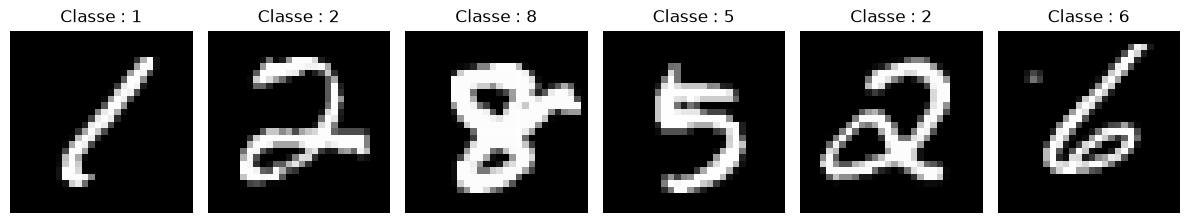

In [46]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i, ax in enumerate(axes):
    image = images[i, 0] * 0.3081 + 0.1307
    ax.imshow(image.cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3. Construire le CNN

Architecture du tableau du sujet :

| Couche | Paramètres | Forme de sortie hors batch |
|---|---|---|
| Entrée | — | 1 × 28 × 28 |
| Convolution + ReLU | 16 filtres, noyau 3, padding 1 | 16 × 28 × 28 |
| Max pooling | noyau 2 | 16 × 14 × 14 |
| Convolution + ReLU | 32 filtres, noyau 3, padding 1 | 32 × 14 × 14 |
| Max pooling | noyau 2 | 32 × 7 × 7 |
| Flatten | — | 1568 |
| Couche linéaire + ReLU | 128 neurones | 128 |
| Couche linéaire | 10 classes | 10 |

La question complémentaire demande un dropout avant la dernière couche linéaire. Il est ajouté avec la probabilité **0,25**. Le dropout ne change pas la forme : l'entrée de la première couche linéaire reste 1 568, et celle de la dernière reste 128. En `eval()`, le dropout est inactif.

Taille de sortie d'une convolution de noyau $k$, padding $p$ et pas $s$ :

$$
\left\lfloor \frac{H + 2p - k}{s} \right\rfloor + 1.
$$

Avec $k = 3$, $p = 1$ et $s = 1$, une carte 28 × 28 reste 28 × 28, et une carte 14 × 14 reste 14 × 14. Chaque max-pooling de noyau 2 divise la hauteur et la largeur par 2 :

$$
28 \times 28 \rightarrow 14 \times 14 \rightarrow 7 \times 7.
$$

D'où $32 \times 7 \times 7 = 1568$ valeurs à l'entrée de la couche dense.

In [47]:
class MNISTClassifier(nn.Module):
    def __init__(self, p_dropout=0.25):
        super().__init__()
        self.p_dropout = p_dropout
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=p_dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = MNISTClassifier(p_dropout=0.25).to(device)
print(model)
print(f"Dropout avant la dernière couche linéaire : p = {model.p_dropout}")
print("Paramètres :", sum(p.numel() for p in model.parameters()))

model.eval()
with torch.no_grad():
    z = images[:1].to(device)
    print("entrée", tuple(z.shape))
    for couche in model.features:
        z = couche(z)
        print(f"{couche.__class__.__name__:12} {tuple(z.shape)}")
    z = model.classifier[0](z)
    print(f"{'Flatten':12} {tuple(z.shape)}")

    sortie = model(images.to(device))

assert sortie.shape == (images.size(0), 10)
print("Sortie :", tuple(sortie.shape), "→ [B, 10] logits, sans softmax")

MNISTClassifier(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Dropout avant la dernière couche linéaire : p = 0.25
Paramètres : 206922
entrée (1, 1, 28, 28)
Conv2d       (1, 16, 28, 28)
ReLU         (1, 16, 28, 28)
MaxPool2d    (1, 16, 14, 14)
Conv2d       (1, 32, 14, 14)
ReLU         (1, 32, 14, 14)
MaxPool2d    (1, 32, 7, 7)
Flatten      (1, 1568)
Sortie : (64, 10) → [B, 10] logits, sans softmax


Le tracé des formes confirme le tableau : le canal passe de 1 à 16 puis à 32, le pooling seul réduit le plan spatial, et l'aplatissement produit 1 568 nombres pour un exemple. L'assertion vérifie que le lot complet ressort en `[B, 10]`. Ces 10 nombres sont les logits envoyés à `CrossEntropyLoss`.

### 4. Entraîner le réseau

Trois époques, Adam à 0,001, cross-entropy sur les logits. La perte moyenne d'époque est la moyenne par image : `loss.item()` est la moyenne du lot, multipliée par la taille du lot, puis divisée par 60 000.

Époque 1/3 | Perte : 0.1928


Époque 2/3 | Perte : 0.0607


Époque 3/3 | Perte : 0.0460


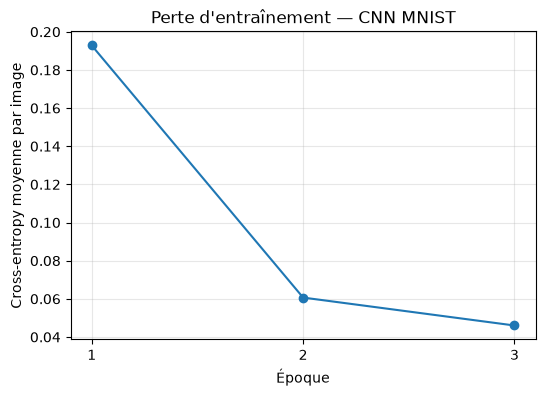

In [48]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad()
        logits = model(batch_images)
        loss = criterion(logits, batch_labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch_images.size(0)
    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("Époque")
plt.ylabel("Cross-entropy moyenne par image")
plt.title("Perte d'entraînement — CNN MNIST")
plt.xticks(range(1, epochs + 1))
plt.grid(True, alpha=0.3)
plt.show()

### 5. Évaluer sur le jeu de test

`argmax(dim=1)` choisit une classe par image. `(predictions == labels).sum()` compte les succès du lot. L'énoncé indique qu'une accuracy généralement supérieure à **97 %** est un repère indicatif, sans garantie exacte. Le nombre retenu est celui mesuré sur les 10 000 images.

In [49]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        logits = model(batch_images)
        predictions = logits.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        total += batch_labels.size(0)

accuracy = correct / total
print(f"Images de test évaluées : {total}")
print(f"Accuracy sur le test : {accuracy:.2%}")
print("Le seuil de 97 % de l'énoncé est un repère indicatif.")
if accuracy >= 0.97:
    print(f"Le score mesuré, {accuracy:.2%}, atteint ce repère.")
else:
    print(f"Le score mesuré, {accuracy:.2%}, reste sous ce repère sur cette exécution.")
assert total == 10000

resultats["cnn"] = {
    "accuracy": float(accuracy),
    "n_test": int(total),
    "correct": int(correct),
    "epochs": 3,
    "perte_finale": float(loss_history[-1]),
    "parametres": int(sum(p.numel() for p in model.parameters())),
    "dropout": 0.25,
}

Images de test évaluées : 10000
Accuracy sur le test : 98.93%
Le seuil de 97 % de l'énoncé est un repère indicatif.
Le score mesuré, 98.93%, atteint ce repère.


### Images mal classées et sauvegarde

On affiche jusqu'à 10 erreurs du test, avec la vraie classe et la prédiction. S'il y en a moins, la cellule affiche celles qui existent et leur nombre. Les pixels sont dénormalisés pour l'affichage.

`torch.save(model.state_dict(), "mnist_cnn.pth")` n'enregistre que les poids. Un second réseau de la même classe recharge le fichier et doit reproduire les logits du modèle entraîné sur un lot réel du test.

Erreurs sur le test : 107 / 10000
Images mal classées affichées : 10


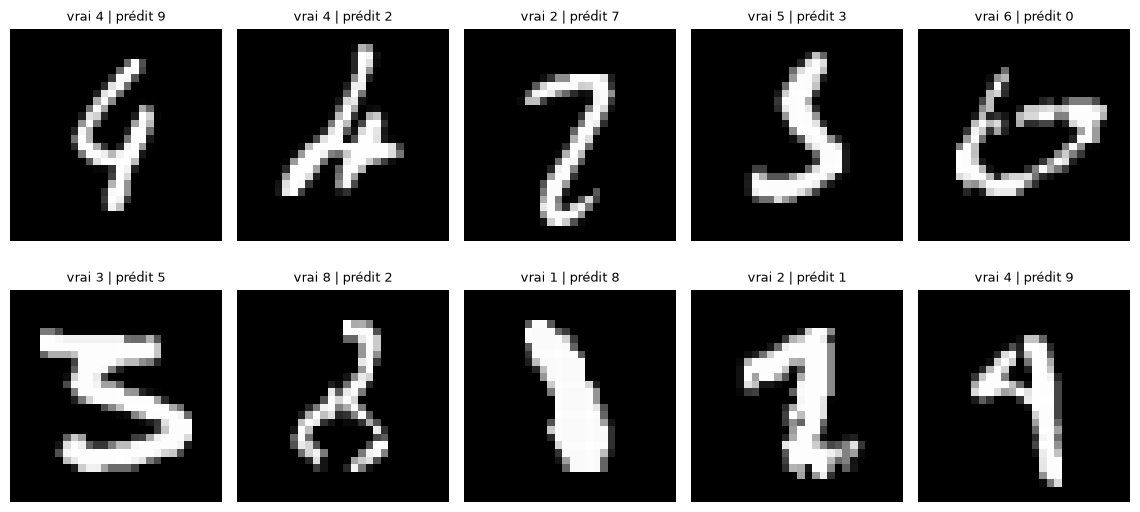

Paramètres enregistrés dans mnist_cnn.pth


CNN rechargé, logits identiques sur un lot de test : True


In [50]:
model.eval()
erreurs_cnn = []
avec_erreur = 0

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        predictions = model(batch_images).argmax(dim=1)
        mauvais = predictions != batch_labels
        avec_erreur += int(mauvais.sum().item())
        for image, vrai, prevu in zip(
            batch_images[mauvais].cpu(),
            batch_labels[mauvais].cpu(),
            predictions[mauvais].cpu(),
        ):
            if len(erreurs_cnn) < 10:
                erreurs_cnn.append((image, int(vrai), int(prevu)))

print(f"Erreurs sur le test : {avec_erreur} / {resultats['cnn']['n_test']}")
print(f"Images mal classées affichées : {len(erreurs_cnn)}")

if len(erreurs_cnn) == 0:
    print("Aucune erreur à afficher.")
else:
    colonnes = 5
    lignes = math.ceil(len(erreurs_cnn) / colonnes)
    fig, axes = plt.subplots(lignes, colonnes, figsize=(2.3 * colonnes, 2.8 * lignes))
    axes = np.atleast_1d(axes).ravel()
    for ax, (image, vrai, prevu) in zip(axes, erreurs_cnn):
        pixels = image[0] * 0.3081 + 0.1307
        ax.imshow(pixels.numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"vrai {vrai} | prédit {prevu}", fontsize=9)
        ax.axis("off")
    for ax in axes[len(erreurs_cnn):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

chemin_cnn = "mnist_cnn.pth"
torch.save(model.state_dict(), chemin_cnn)
print("Paramètres enregistrés dans", chemin_cnn)

modele_cnn_neuf = MNISTClassifier(p_dropout=0.25).to(device)
lot_images, _ = next(iter(test_loader))
lot_images = lot_images.to(device)
model.eval()
modele_cnn_neuf.eval()
with torch.no_grad():
    ref = model(lot_images)
modele_cnn_neuf.load_state_dict(torch.load(chemin_cnn, map_location=device, weights_only=True))
modele_cnn_neuf.eval()
with torch.no_grad():
    relu = modele_cnn_neuf(lot_images)
print("CNN rechargé, logits identiques sur un lot de test :", bool(torch.allclose(ref, relu)))
assert torch.allclose(ref, relu)
resultats["cnn"]["erreurs"] = int(avec_erreur)

# Conclusion

## Quelle perte pour quelle tâche

La **MSE** convient aux cibles continues. Elle mesure le carré de l'écart et, pour un bruit gaussien comme celui des salaires ou de la droite $3x + 2$, sa valeur minimale théorique est la variance de ce qui reste imprévisible. C'est la perte des deux régressions de ce notebook.

La **cross-entropy** convient aux classes exclusives. Elle reçoit des logits et l'indice entier de la classe ; le `log_softmax` est interne. C'est la perte d'Iris (3 espèces), du MLP et du CNN (10 chiffres). La **BCE avec logits** reste l'alternative lorsqu'on ne produit qu'un seul score binaire. La démonstration à deux nuages a plutôt utilisé deux logits et la cross-entropy, ce qui est cohérent avec un `argmax` entre deux classes.

Dans tous les classifieurs, le softmax n'est pas dans le modèle. Le placer avant la cross-entropy appliquerait deux fois une normalisation et dégraderait l'apprentissage.

## MLP et CNN : deux configurations, un même test

Les deux modèles sont évalués sur les **mêmes 10 000 images officielles** de test MNIST. Ce ne sont pas pour autant deux variantes isolées d'une même expérience :

- le MLP est entraîné **5 époques** sur des pixels seulement ramenés à $[0, 1]$ par `ToTensor()` ;
- le CNN est entraîné **3 époques**, avec en plus `Normalize((0.1307,), (0.3081,))`, des convolutions, un pooling et un dropout de probabilité 0,25.

Le MLP voit chaque pixel comme une variable parmi 784. Le CNN construit d'abord des cartes locales (16 puis 32 filtres) et ne densifie qu'après être passé de $28 \times 28$ à $7 \times 7$. La comparaison porte donc sur deux configurations complètes.

Sur l'exécution de ce notebook, le MLP (101 770 paramètres, 5 époques) atteint **97,41 %** d'accuracy, **97,41 %** de précision macro, **97,40 %** de rappel macro et **97,40 %** de F1 macro, sur 10 000 images. Le CNN (206 922 paramètres, dropout 0,25, 3 époques, pixels normalisés) atteint **98,93 %** d'accuracy, soit 107 erreurs. L'écart est d'environ 1,5 point, en faveur du CNN, alors qu'il a vu moins d'époques. Ce gain est compatible avec les filtres locaux et avec la normalisation, sans qu'on puisse attribuer les 1,5 point à un seul de ces choix. Les deux restent au-dessus du repère indicatif de 97 % du CNN, qui n'était pas une cible à recopier. La cellule suivante réimprime ces mesures à partir des variables de l'exécution.

In [51]:
from pathlib import Path

mlp = resultats["mlp"]
cnn = resultats["cnn"]
salaire = resultats["salaire"]
iris_res = resultats["iris"]

print("Récapitulatif de cette exécution")
print(
    f"Démonstration régression : w = {resultats['demo_regression']['w']:.3f}, "
    f"b = {resultats['demo_regression']['b']:.3f}, "
    f"R² entraînement = {resultats['demo_regression']['r2_entrainement']:.3f}"
)
print(
    f"Démonstration classification : accuracy entraînement = "
    f"{resultats['demo_classification']['accuracy_entrainement']:.2%} "
    f"sur {resultats['demo_classification']['effectif']} points"
)
print(
    f"Exercice 1 — MAE test = {salaire['mae_test_dh']:.2f} DH ; "
    f"prédiction (7 ans, expertise 4) = {salaire['prediction_7_4']:.2f} DH "
    f"(écart à 14 200 : {salaire['ecart_14200']:+.2f} DH)"
)
print(
    f"Exercice 1 — coefficients retrouvés : ancienneté {salaire['coef_anciennete']:.1f}, "
    f"expertise {salaire['coef_expertise']:.1f}, origine {salaire['ordonnee']:.1f}"
)
print(
    f"Exercice 1 — MAE contrôlée, bruit 500 DH = {salaire['mae_bruit_500']:.2f} ; "
    f"bruit 1 500 DH = {salaire['mae_bruit_1500']:.2f}"
)
print(
    f"Exercice 2 — accuracy réseau = {iris_res['accuracy']:.1%} ; "
    f"accuracy linéaire = {iris_res['accuracy_lineaire']:.1%} ; "
    f"matrice = {iris_res['somme_matrice']} fleurs ; "
    f"nouvelle fleur → {iris_res['espece_reseau']} (linéaire : {iris_res['espece_lineaire']})"
)
print(
    f"Exercice 3 — MLP, {mlp['epochs']} époques, {mlp['parametres']} paramètres, "
    f"{mlp['n_test']} images : accuracy {mlp['accuracy']:.2%}, "
    f"précision macro {mlp['precision']:.2%}, rappel macro {mlp['recall']:.2%}, "
    f"F1 macro {mlp['f1']:.2%}, matrice {mlp['somme_matrice']}"
)
print(
    f"Exercice 4 — CNN, {cnn['epochs']} époques, dropout {cnn['dropout']}, "
    f"{cnn['parametres']} paramètres, {cnn['n_test']} images : "
    f"accuracy {cnn['accuracy']:.2%}, erreurs {cnn['erreurs']}"
)

if cnn["accuracy"] > mlp["accuracy"]:
    print(
        "Sur cette exécution, la configuration CNN obtient une accuracy de test "
        "plus élevée que la configuration MLP, malgré moins d'époques. "
        "L'écart est compatible avec l'extraction locale des convolutions "
        "et avec la normalisation propre au CNN ; il ne sépare pas ces facteurs."
    )
elif cnn["accuracy"] < mlp["accuracy"]:
    print(
        "Sur cette exécution, la configuration MLP obtient une accuracy de test "
        "plus élevée. Il a eu davantage d'époques et un prétraitement différent. "
        "Ce résultat ne dit pas qu'un CNN serait inférieur à protocole égal."
    )
else:
    print(
        "Sur cette exécution, les deux configurations ont la même accuracy de test. "
        "Les prétraitements et le nombre d'époques diffèrent encore."
    )

for nom in ["mnist_mlp.pth", "mnist_cnn.pth", "classifier_state_dict.pt"]:
    fichier = Path(nom)
    print(f"{nom} : existe = {fichier.exists()}, taille = {fichier.stat().st_size} octets")

Récapitulatif de cette exécution
Démonstration régression : w = 2.989, b = 2.030, R² entraînement = 0.972
Démonstration classification : accuracy entraînement = 100.00% sur 240 points
Exercice 1 — MAE test = 381.64 DH ; prédiction (7 ans, expertise 4) = 14201.94 DH (écart à 14 200 : +1.94 DH)
Exercice 1 — coefficients retrouvés : ancienneté 592.7, expertise 1490.7, origine 4090.3
Exercice 1 — MAE contrôlée, bruit 500 DH = 381.64 ; bruit 1 500 DH = 1144.93
Exercice 2 — accuracy réseau = 100.0% ; accuracy linéaire = 90.0% ; matrice = 30 fleurs ; nouvelle fleur → setosa (linéaire : setosa)
Exercice 3 — MLP, 5 époques, 101770 paramètres, 10000 images : accuracy 97.41%, précision macro 97.41%, rappel macro 97.40%, F1 macro 97.40%, matrice 10000
Exercice 4 — CNN, 3 époques, dropout 0.25, 206922 paramètres, 10000 images : accuracy 98.93%, erreurs 107
Sur cette exécution, la configuration CNN obtient une accuracy de test plus élevée que la configuration MLP, malgré moins d'époques. L'écart est